In [ ]:
# Реализуйте высокочастотную фильтрацию на основе ядра Гаусса
# Реализуйте вычисление свертки с помощью преобразования Фурье
# Реализуйте удаление периодического шума с помощью преобразования Фурье

In [1]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

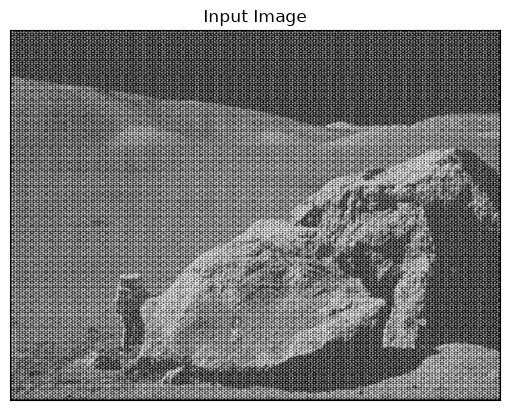

In [19]:
img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)
plt.imshow(img, cmap='gray')
plt.title('Input Image')
plt.xticks([]), plt.yticks([])
plt.show()

In [4]:
# Задание 1
f = np.fft.fft2(img)
fshift = np.fft.fftshift(f)

rows, cols = img.shape
crow, ccol = rows // 2, cols // 2
D0 = 30

In [5]:
u = np.arange(cols) - ccol
v = np.arange(rows) - crow
U, V = np.meshgrid(u, v)
D = np.sqrt(U**2 + V**2)

In [6]:
mask_hp = 1 - np.exp(-(D**2) / (2 * D0**2))

fshift_filtered = fshift * mask_hp

f_ishift = np.fft.ifftshift(fshift_filtered)
img_back_hp = np.abs(np.fft.ifft2(f_ishift))

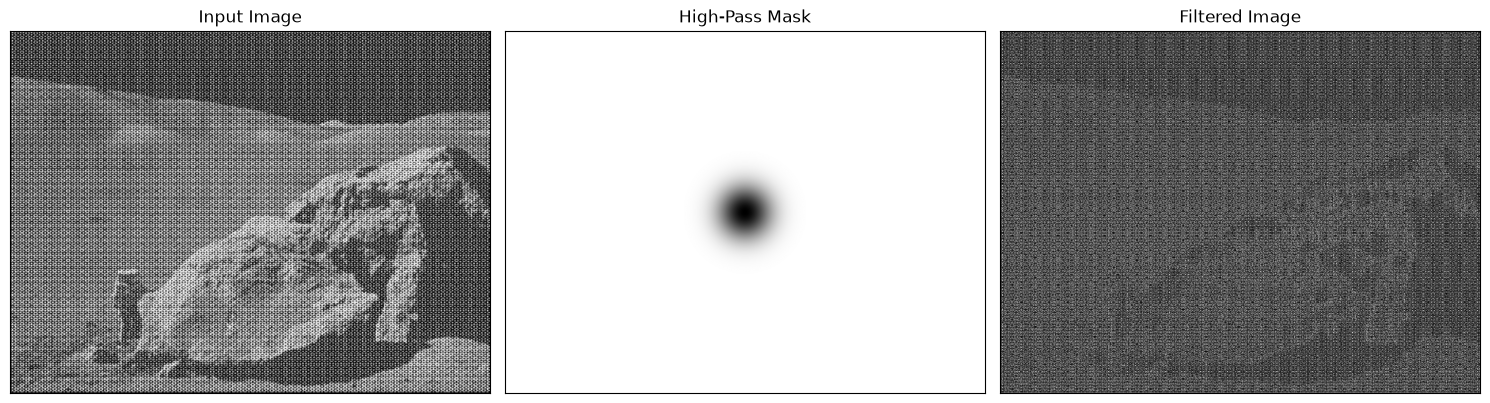

In [7]:
plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(mask_hp, cmap='gray')
plt.title('High-Pass Mask'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(img_back_hp, cmap='gray')
plt.title('Filtered Image'), plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

In [8]:
# Задание 2
kernel_size = 15
sigma = 3
kernel_1d = cv.getGaussianKernel(kernel_size, sigma)
kernel_2d = np.outer(kernel_1d, kernel_1d)

In [9]:
kernel_padded = np.zeros_like(img, dtype=np.float32)
kernel_padded[:kernel_size, :kernel_size] = kernel_2d

kernel_padded = np.roll(kernel_padded, -kernel_size // 2, axis=0)
kernel_padded = np.roll(kernel_padded, -kernel_size // 2, axis=1)

In [10]:
F_img = np.fft.fft2(img)
F_kernel = np.fft.fft2(kernel_padded)
F_conv = F_img * F_kernel

img_conv_fft = np.abs(np.fft.ifft2(F_conv))
img_conv_spatial = cv.filter2D(img, -1, kernel_2d)

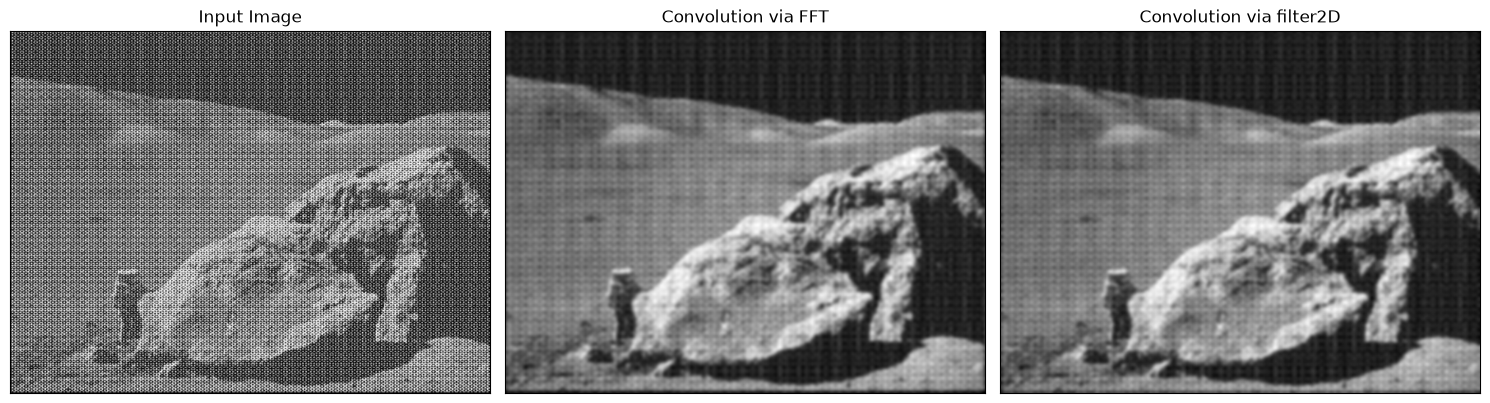

In [11]:
plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(img_conv_fft, cmap='gray')
plt.title('Convolution via FFT'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(img_conv_spatial, cmap='gray')
plt.title('Convolution via filter2D'), plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

In [13]:
# Задание 3
f = np.fft.fft2(img)
fshift = np.fft.fftshift(f)
magnitude_spectrum = 20 * np.log(np.abs(fshift) + 1e-5)

notch_mask = np.ones_like(img, dtype=np.float32)
crow, ccol = rows // 2, cols // 2


In [15]:
threshold = np.percentile(magnitude_spectrum, 99.5)
peaks = np.argwhere(magnitude_spectrum > threshold)

In [16]:
for y, x in peaks:
    if np.sqrt((y - crow)**2 + (x - ccol)**2) > 20:
        cv.circle(notch_mask, (x, y), 5, 0, -1)
        cv.circle(notch_mask, (cols - 1 - x, rows - 1 - y), 5, 0, -1)

In [17]:
fshift_filtered = fshift * notch_mask

f_ishift = np.fft.ifftshift(fshift_filtered)
img_back_notch = np.abs(np.fft.ifft2(f_ishift))

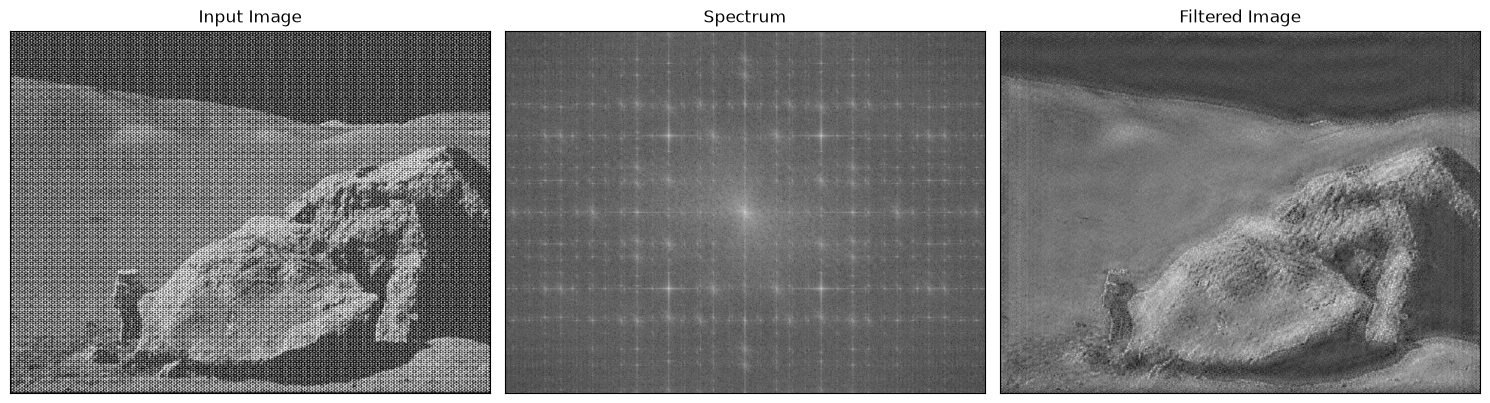

In [18]:
plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(magnitude_spectrum, cmap='gray')
plt.title('Spectrum'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(img_back_notch, cmap='gray')
plt.title('Filtered Image'), plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()